<a href="https://colab.research.google.com/github/Panlyzar/project_suui2/blob/main/SUI_CV7__Optimalizace_neuronov%C3%BDch_s%C3%ADt%C3%AD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📒 CVIČENÍ 7. -  Optimalizace neuronových sítí
---
Tohle cvičení bude zaměřeno především na praktické experimentování s optimaliací neuronových síťí. 🦾 Plynule zde navážeme na předchozí cvičení a budeme v něm pokračovat ve snaze najít optimální model a ukážeme si některé nástroje k ušetření práce. 🔧






In [ ]:
# Import základních ML knihoven - best practices
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Knihovny TensorFlow pro práci s neuronovými sítěmi
import tensorflow as tf

#Knihovny pro práci s OS a časem
import datetime, os

In [ ]:
# Definice funkce která převádí pole na obrázek
from PIL import Image

def arr_to_bmp(array_data, mode="RGB", size=(64,64)):
  img = Image.fromarray(array_data, mode).resize(size)
  return img

## 📃 ČÁST 1: Příprava dat: MNIST (Modified National Institute of Standards and Technology)
---

**📘 Popis**
**MNIST** je klasický dataset používaný pro trénink a testování algoritmů **strojového učení**, zejména v oblasti **rozpoznávání rukopisných číslic**.  
Obsahuje **rukou psané číslice 0–9** extrahované z formulářů amerického úřadu NIST a normalizované do jednotného formátu.

Dataset je považován za *"Hello World"* úlohu pro hluboké učení.

---

**🧩 Struktura a formát dat**
- **Počet vzorků:**  
  - Trénovací sada: `60 000` obrázků  
  - Testovací sada: `10 000` obrázků  
- **Rozměr obrázků:** `28 × 28` pixelů  
- **Počet kanálů:** `1` (odstíny šedi)  
- **Rozsah hodnot pixelů:** `0–255` (často normalizováno na `0–1`)  
- **Datový typ:** `uint8`  
- **Formát:**  
  - `train-images-idx3-ubyte` – trénovací obrázky  
  - `train-labels-idx1-ubyte` – trénovací štítky  
  - `t10k-images-idx3-ubyte` – testovací obrázky  
  - `t10k-labels-idx1-ubyte` – testovací štítky

---

**🔢 Třídy (labely)**
Dataset obsahuje **10 tříd**, odpovídajících číslicím:
| Label | Popis |
|:------:|:------|
| 0 | Číslice „0“ |
| 1 | Číslice „1“ |
| 2 | Číslice „2“ |
| 3 | Číslice „3“ |
| 4 | Číslice „4“ |
| 5 | Číslice „5“ |
| 6 | Číslice „6“ |
| 7 | Číslice „7“ |
| 8 | Číslice „8“ |
| 9 | Číslice „9“ |

---


In [ ]:
#Rychlý náhled dat
# Náhled dat - vizualizace (prvních 10)
def show_img_preview(images, labels, map_func = None, map:dict = None, n=16):
  for i in range(n):
      plt.subplot(int(n/4), int(n/4), i+1)
      plt.imshow(images[i], cmap='gray')
      if map_func:
        plt.title(f'{map_func(labels[i], map)}')
      else:
        plt.title(f'{labels[i]}')
      plt.axis('off')

  # Zarovná layout
  plt.tight_layout()

In [ ]:
# Import MNIST datasetu
mnist = tf.keras.datasets.mnist

# Načtení CIFAR-10 dataset
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


### 🔭 Explorační analýza
*Není třeba provádět důkladnou analýzu, jedná se o čistý dataset.*

In [ ]:
# Zkontrolujeme shape a počet dat
train_images.shape, train_images.ndim, test_images.shape, test_images.ndim

((60000, 28, 28), 3, (10000, 28, 28), 3)

In [ ]:
train_labels.shape, test_labels.shape

((60000,), (10000,))

✍ *Vsuvka:* Všimnite si tvaru vstupních dat - `train_images`. Mají tvar `(60000, 28, 28)`, což značí 60000 obrázků, 28 pixelů / řádek,28 pixelů / sloupec.

/tmp/ipython-input-2284591411.py:5: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(array_data, mode).resize(size)


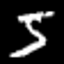

In [ ]:
arr_to_bmp(train_images[0], "L")

In [ ]:
train_labels[0]

np.uint8(5)

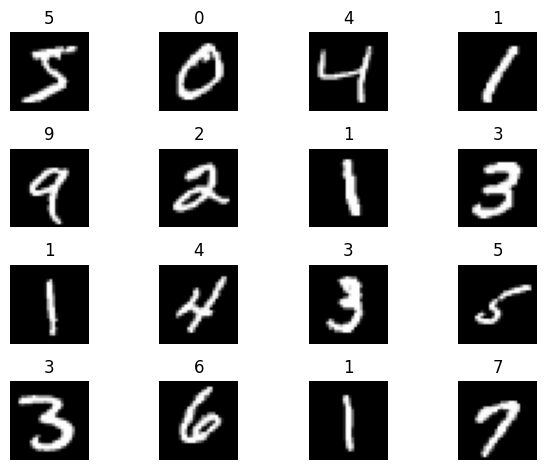

In [ ]:
show_img_preview(train_images, train_labels.reshape(-1))

## ✂️ Rozdělení, úprava a normalizace dat
Postupujeme stejně jako v předchozím cvičením. Trénovací a testovací množiny ukládáme do `X_train`, `X_test`, `y_train` a `y_test`.

In [ ]:
X_train = train_images
X_test = test_images

y_train = train_labels
y_test = test_labels

X_train.shape, X_test.shape, y_train.shape, y_test.shape

## 🪄 Augmentace dat
Pomocí augmentace dat si můžeme uměle vytvořit úpravou strých dat, data nová. ✨Většinou se tohle provádí u obrazových abychom  zvětšili trénovací množinu a zlepšili generalizaci modelu. Augmentované data vytvoříme z trénovacích dat.



> Knihovna `imgaug`: https://imgaug.readthedocs.io/en/latest/



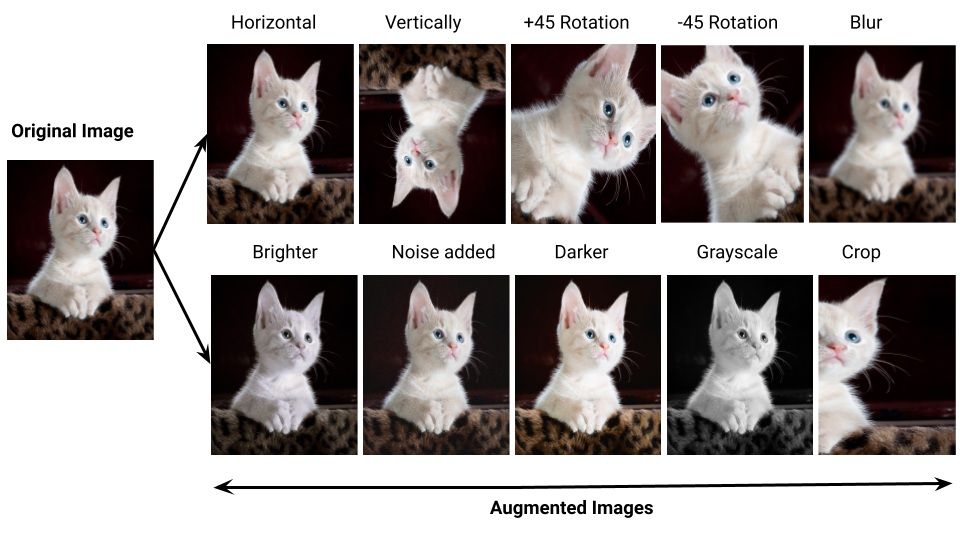

In [ ]:
!pip install imgaug

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 948.0/948.0 kB 28.4 MB/s eta 0:00:00


### Fix for `imgaug` error:

Go to:
[/usr/local/lib/python3.12/dist-packages/imgaug/imgaug.py](/usr/local/lib/python3.12/dist-packages/imgaug/imgaug.py)



Replace:
```
# to check if a dtype instance is among these dtypes, use e.g.
# `dtype.type in  NP_FLOAT_TYPES` do not just use `dtype in NP_FLOAT_TYPES` as
# that would fail
NP_FLOAT_TYPES = set(np.sctypes["float"])
NP_INT_TYPES = set(np.sctypes["int"])
NP_UINT_TYPES = set(np.sctypes["uint"]
```

by:

```
NP_FLOAT_TYPES = {np.float16, np.float32, np.float64}
NP_INT_TYPES = {np.int8, np.int16, np.int32, np.int64}
NP_UINT_TYPES = {np.uint8, np.uint16, np.uint32, np.uint64}
```

In [ ]:
#Použijeme knihovnu imgaug
import imgaug.augmenters as iaa

# Definice augmentoru
augmentor = iaa.Sequential([
    iaa.Crop(px=(0, 4)), # Ořezání obrázku o 0 až 4 pixelů na každé straně
    iaa.Fliplr(0.5), # Horizontální převrácení s 50% pravděpodobností,
    iaa.Flipud(0.5), # Vertikální převrácení s 50% pravděpodobností,
    iaa.Affine(rotate=45),  # Rotace o 45 st.
    iaa.GammaContrast((0.5, 2.0)) #Uprav kontrast
])

# Příprava vstupních dat
X_aug = augmentor.augment_images(images=X_train[:16])

AttributeError: module 'imgaug.imgaug' has no attribute 'deprecated'

In [ ]:
show_img_preview(X_aug, y_train.reshape(-1))

### 🧠 ÚKOL 1:

Vyzkoušej různé možnosti augmentace dat a vytvoř dualní syntetický dataset k originálnímu datasetu. Můžeš si pak vytvořit vlastní trénovací množinu spojením originálu (`X_train`) a syntetiky (`X_aug`) - použij `np.concat`. Nezapomeňte rozšířit i výstupy o `y_aug`.'

In [ ]:
### řešení úkolu č. 1:
X_train_aug = ???
y_train_aug = ???

### Normalizace a redukce dimenze

In [ ]:
X_train_aug, X_test = X_train_aug/255.0, X_test/255.0

✍ *Vsuvka:* Stejně jako posledně, je zde min 0, tedy ho lze vynechat a prostě vydělit dataset maximem - 255. ➗

In [ ]:
# Ubereme dimenze
X_train_aug = X_train_aug.reshape(-1, 28*28)
X_test = X_test.reshape(-1, 28*28)

X_train_aug.shape, X_test.shape

## ✅ Validační data
Validační data se používají k on-run ověřování výkonnosti a přesnosti modelu při trénování. Validační data vytvoříme z testovacích dat.

In [ ]:
from sklearn.model_selection import train_test_split

X_test, X_val, y_test, y_val =  train_test_split(X_test, y_test, test_size=0.1)
X_test.shape, y_test.shape, X_val.shape, y_val.shape

# ⭐ Vytvoření modelů
Dataset je připraven, nyní nám stačí vytvořit, natrénovat a otestovat model.  

In [ ]:
# Zobraz historii jako graf
def show_history(history, ignore_val = True):
    plt.figure()
    for key in history.history.keys():
      if key.find("val") != -1 and ignore_val:
        continue
      plt.plot(history.epoch, history.history[key], label=key)
    plt.legend()
    plt.tight_layout()

In [ ]:
# Funkce pro převod mezi distribucí pravděpodobnosti a číslem třídy
def prob_to_class(p):
  c =  np.argmax(p)
  return c

def probs_to_classes(probs):
  classes = []
  for p in probs:
    c =  prob_to_class(p)
    classes.append(c)

  return np.array(classes)

## 🧩 Model 1: Dense **bez** optimalizace

Použijeme jednoduchý Dense model se základními parametry.

In [ ]:
 # Vytvoření modelu

 # Vstupní vrstva
input_layer = tf.keras.layers.Input(shape=(28*28,))
 # Skryté vrstvy
x = tf.keras.layers.Dense(units=32, activation='relu')(input_layer)
x = tf.keras.layers.Dense(units=32, activation='relu')(x)
 # Výstupní vrstva
output_layer = tf.keras.layers.Dense(units=10, activation='softmax')(x)

# Sestavení modelu
model_no_opt = tf.keras.Model(input_layer, output_layer)
model_no_opt.summary()

In [ ]:
# Kompilace modelu - pomocí textových aliasů
model_no_opt.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [ ]:
# Fit s validací BEZ callbacků
epochs = 10
batch_size = 32
history = model_no_opt.fit(X_train_aug, y_train_aug, epochs=epochs, batch_size=batch_size)

In [ ]:
# Vyhodnocení přesnosti modelu
loss, sparse_categorical_accuracy = model_no_opt.evaluate(X_test, y_test)
loss, sparse_categorical_accuracy

## 🧩 Model 1: Dense **s** optimalizací

In [ ]:
 # Vytvoření modelu - funkce

def make_model(input_shape:tuple, output_shape:int, layers:list, dropout_level = 0.1):
  # Vstupní vrstva
  input_layer = tf.keras.layers.Input(shape=input_shape)
  # Skryté vrstvy
  for i,layer in enumerate(layers):
    # First layer needs input
    if i == 0:
      x = tf.keras.layers.Dense(units=layer["units"], activation=layer.get("activation", "relu"), kernel_regularizer=tf.keras.regularizers.l1_l2(layer.get("l1", 0.0), layer.get("l2", 0.0)))(input_layer)
    else:
      x = tf.keras.layers.Dense(units=layer["units"], activation=layer.get("activation", "relu"), kernel_regularizer=tf.keras.regularizers.l1_l2(layer.get("l1", 0.0), layer.get("l2", 0.0)))(x)
  # Dropout vrstva pro lepší generalizaci
  if dropout_level:
    x = tf.keras.layers.Dropout(dropout_level)(x)
  # Výstupní vrstva
  output_layer = tf.keras.layers.Dense(units=output_shape, activation='softmax')(x)

  # Sestavení modelu
  model = tf.keras.Model(input_layer, output_layer)

  # Kompilace modelu - pomocí textových aliasů
  model.compile(optimizer='adam',
                loss='sparse_categorical_crossentropy',
                metrics=['accuracy'])
  model.summary()
  return model

### 💪 Trénování modelu

### 🛑 Early Stopping
K předčastnému automatickému zastavení trénování sítě můžeme použít callback `EarlyStopping`.
- `monitor`: atribut který říká co chceme monitorovat - co bude rozhodovat o zastavení trénování
- `min_delta`: minimální rozdíl oproti staré hodnotě aby se trénování nezastavilo
- `patience`: trpělivost, kolikrát bude callback čekat než sepne

### ✅📈  Fit + Validate + Callbacks + Trials

In [ ]:
# Příprava architektrur
architectures = [
{
    "layers":[{"units":32}, {"units":32}],
    "dropout_level" : None
},
{
    "layers":[{"units":128}, {"units":64}],
    "dropout_level" : 0.1
},
{
    "layers":[{"units":128, "l1":0.001, "l2":0.001}, {"units":64}, {"units":16}],
    "dropout_level" : 0.2
},
]

In [ ]:
# Trénování modelu pomocí trials architectures
trials = 3

best_result = None
best_arch = None
best_model = None
best_history = None

for arch in architectures:
  print("Testing arch:", arch)
  for i in range(trials):
    print(f"Running trial {i}...")
    # Early Stopping callback
    early_stopping_callback = tf.keras.callbacks.EarlyStopping(monitor='loss', min_delta=0.01, patience=3)

    # TensorBoard Stopping callback
    logdir = os.path.join("logs", datetime.datetime.now().strftime("%Y%m%d-%H%M%S"))
    tensorboard_callback = tf.keras.callbacks.TensorBoard(logdir, histogram_freq=1)

    # Fit s validací a callbacky
    epochs = 50
    batch_size = 32
    # Pužiji i validační data
    model_opt = make_model(input_shape=(28*28,), output_shape=10, **arch)
    history = model_opt.fit(X_train_aug, y_train_aug, validation_data=(X_val, y_val), callbacks=[early_stopping_callback, tensorboard_callback], epochs=epochs, batch_size=batch_size)
    show_history(history, ignore_val = False)
    # Evaulace modelu
    loss, sparse_categorical_accuracy = model_opt.evaluate(X_test, y_test)
    # Uložení nejlepšího modelu
    if not best_result or best_result < sparse_categorical_accuracy:
      print(f"***New best model found! Score:{sparse_categorical_accuracy}")
      best_result = sparse_categorical_accuracy
      best_model = model_opt
      best_arch = arch
      best_history = history
      # Uložení vah do souboru
      best_model.save_weights(f"dense_best.weights.h5")
    print("-"*50)
print("*"*50)

✍ *Vsuvka:* Trénování modelu zabere nějaký čas, je třeba pár min počkat ⏰ Vidíme ale že `EarlyStopping` callback zastavil trénování dříve než v 50 epoše.

✍ *Vsuvka:* Loss - ztráta by měla postupně klesat k 0 📉, accuracy - přesnost by měla naopak stoupat k 1.0 📈

⏰ Tohle nějakou chviku zabere...

In [ ]:
print(f"Best score = {best_result}, best arch: {best_arch}")
# Load model from file

best_model = make_model(input_shape=(28*28,), output_shape=10, **best_arch)
best_model.load_weights(r"/content/dense_best.weights.h5")

In [ ]:
show_history(best_history, ignore_val=False)

#### 👈 TensorBoard
Pro pohlednější sledování průběhů a metrik použijeme TensorBoard

In [ ]:
# Načti TensorBoard notebook extension
%load_ext tensorboard

In [ ]:
# Spusť TensorBoard
%tensorboard --logdir logs

#### WandB
Krátké demo pro demonstraci WandB - alternativa k `TensorBoard`,
registrace zde: https://wandb.ai/site

In [ ]:
# Instalace balíčku WandB
!pip install wandb

In [ ]:
# Log-In
# Načti svůj API key (dostaneš ho po registraci)
wandb_api_key = input("Put your API key here:")
!wandb login wandb_api_key

In [ ]:
import wandb
import random

# start a new wandb run to track this script
wandb.init(
    # set the wandb project where this run will be logged
    project="cv7_ssui",
    name = "MNIST_3",
    # track hyperparameters and run metadata
    config={
    "architecture": "Dense",
    "dataset": "MNIST",
    "epochs": 12,
    }
)

# log metrics to wandb
for k in best_history.history.keys():
  for v in best_history.history[k]:
    wandb.log({k:v})

# [optional] finish the wandb run, necessary in notebooks
wandb.finish()

## 🖌️ **Canvas**

### Engine

In [ ]:
!pip install ipycanvas

In [ ]:
from google.colab import output
output.enable_custom_widget_manager()

In [ ]:
import numpy as np
from PIL import Image, ImageOps
from IPython.display import display, HTML, Javascript
from google.colab.output import eval_js

def get_drawing_robust(width=200, height=200):
    """
    Robustní verze pro opakované spuštění.
    """
    # Vygeneruje unikátní ID pro prvky, aby se předešlo konfliktům
    container_id = f"drawing_container_{np.random.randint(100000)}"

    # HTML kód s div pro umístění plátna a tlačítka
    html_code = f"""
        <div id="{container_id}">
            <canvas id="canvas_{container_id}" width="{width}" height="{height}" style="border: 1px solid black;"></canvas>
            <button id="button_{container_id}">Uložit kresbu a pokračovat</button>
        </div>
    """
    display(HTML(html_code))

    # JavaScript pro kreslení a získání dat
    js_code = f"""
        (function() {{
            const container = document.getElementById('{container_id}');
            const canvas = document.getElementById('canvas_{container_id}');
            const button = document.getElementById('button_{container_id}');
            const ctx = canvas.getContext('2d');

            // ... (Zbytek JS kódu pro kreslení je stejný) ...
            ctx.lineWidth = 15;
            ctx.lineCap = 'round';
            ctx.strokeStyle = 'black';
            ctx.fillStyle = 'white';
            ctx.fillRect(0, 0, canvas.width, canvas.height);

            let isDrawing = false;
            canvas.addEventListener('mousedown', (e) => {{
                isDrawing = true;
                ctx.beginPath();
                ctx.moveTo(e.offsetX, e.offsetY);
            }});
            canvas.addEventListener('mousemove', (e) => {{
                if (isDrawing) {{
                    ctx.lineTo(e.offsetX, e.offsetY);
                    ctx.stroke();
                }}
            }});
            canvas.addEventListener('mouseup', () => {{ isDrawing = false; }});
            canvas.addEventListener('mouseout', () => {{ isDrawing = false; }});
            // -----------------------------------------------------------------

            return new Promise(resolve => {{
                button.onclick = () => {{
                    const dataUrl = canvas.toDataURL('image/png');
                    // Odstraní celý kontejner, aby se vyčistila buňka
                    container.remove();
                    resolve(dataUrl);
                }};
            }});
        }})() // Okamžité spuštění anonymní funkce
    """

    data_url = eval_js(js_code)
    # Zpracování dataUrl (dekódování, konverze na BW pole) - STEJNÉ JAKO PŘEDTÍM
    import base64
    from io import BytesIO
    from PIL import Image

    header, encoded = data_url.split(",", 1)
    img_data = base64.b64decode(encoded)
    img = Image.open(BytesIO(img_data))
    img = img.resize((28, 28)).convert('L')
    # Invert image
    img = ImageOps.invert(img)
    bw_array = np.array(img)

    return bw_array

# --- Zkusit spustit robustní verzi ---
# print("Nakreslete něco do rámečku níže (ideálně číslici) a klikněte na 'Uložit'.")
# try:
#     drawing_data_bw = get_drawing_robust(width=200, height=200)
#     print(f"Tvar pole: {drawing_data_bw.shape}")
# except Exception as e:
#     print(f"Chyba při spuštění: {e}")

### ✅ Test

Otestujeme oba modely - `model_no_opt` a `model_opt` na datech které ještě neviděli - naše vlastní vstupy.

In [ ]:
print("Nakreslete něco do rámečku níže (ideálně číslici) a klikněte na 'Uložit'.")
try:
    drawing_data_bw = get_drawing_robust(width=280, height=280)
    print(f"Tvar pole: {drawing_data_bw.shape}")
except Exception as e:
    print(f"Chyba při spuštění: {e}")

In [ ]:
drawing_data_bw

In [ ]:
# Normalizace pro NN modely
drawing_data_bw_norm = drawing_data_bw.reshape(1, 28*28) / 255

In [ ]:
predicted = model_no_opt.predict(drawing_data_bw_norm)
pred_class = probs_to_classes(predicted)
pred_class

In [ ]:
predicted = model_opt.predict(drawing_data_bw_norm)
pred_class = probs_to_classes(predicted)
pred_class

🧠 ÚKOL 2:: **Vlastní model i dataset**

- místo datasetu `MNIST` načtěte dataset `FASHION MNIST`(tf.keras.datasets.fashion_mnist)
- zobrazte prvních 16 vzorků z datasetu včetně labelů
- připravte si data (train, test, validate), včetně normalizace a úpravy dimenze
- vytvořte a netrénujte vlastní model neuronové sítě pro klasifikaci tohoto datasetu
- vykreslete metriky a predikci
- navrhněte několik rozdílných architektur a natrénujte je


# Keras Tuner

V praxi využijime spíše již existující nástroje, např.: [Keras Tuner](https://keras.io/keras_tuner/)

## Fashion Mnist
Tento dataset byl vytvořen jako alternativa k tradičnímu MNIST datasetu, který obsahuje černobílé obrázky ručně psaných číslic.

Fashion MNIST se skládá z **60 000 trénovacích obrázků a 10 000 testovacích** obrázků, každý o **velikosti 28x28 pixelů**. Obrázky zobrazují oblečení a doplňky v **deseti** různých kategoriích:

- T-shirt/Top (Tričko nebo top)
- Trouser (Kalhoty)
- Pullover (Pulovr)
- Dress (Šaty)
- Coat (Kabát)
- Sandal (Sandále)
- Shirt (Košile)
- Sneaker (Tenisky)
- Bag (Kabelka)
- Ankle boot (Kotníková bota)

In [ ]:
# Import a načtení FASHION MNIST datasetu
(train_images, train_labels), (test_images, test_labels) = tf.keras.datasets.fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
def index_to_class(index:int, map:dict):
  class_name = "?"
  if int(index) in map:
    class_name = map[index]

  return class_name

In [ ]:
# Slovník pro překlad - mapa, píše se ve tvaru key:value
fashion_mnist_class_dict = {0:"T-shirt/Top", 1:"Trouser", 2:"Pullover", 3:"Dress", 4:"Coat", 5:"Sandal", 6:"Shirt", 7:"Sneaker", 8:"Bag",9:"Ankle boot ",}

In [ ]:
#Náhled dat
show_img_preview(train_images, train_labels, index_to_class, fashion_mnist_class_dict)

In [ ]:
# Rozdělení dat train/test
X_train = train_images
y_train = train_labels

X_test = test_images
y_test = test_labels

In [ ]:
# Normalizace dat
X_train, X_test = X_train/255.0, X_test/255.0

In [ ]:
X_train.shape, y_train.shape

In [ ]:
# Úprava dimenze na 2D data
X_train = X_train.reshape(-1, 28*28)
X_test = X_test.reshape(-1, 28*28)

In [ ]:
# Vytvoření validačních dat z test dat
X_test, X_val, y_test, y_val = train_test_split(X_test, y_test, test_size=0.2)

**Optimalizace modelu**
- navrhněte několik rozdílných architektur a natrénujte je
- zkuste použít regulace Dropout, L1 a L2
- zkuste použít EarlyStopping callback při trénování
- porovnejte modely navzájem

In [ ]:
# Architektury


In [ ]:
# Trénovací aa evaulační proces (arch + trials + callbacks)
# Ukládej všechny výsledky i modely

In [ ]:
# Výpis nejlepšího modelu a nejhoršího modelu

In [ ]:
# Predikce 16 vzorlů pomocí nejlepšího modelu a nejhoršího modelu

In [ ]:
# Nezapomen použít konverzi
y_pred_classes = probs_to_classes(y_predict)
y_pred_classes

In [ ]:
#Náhled - zkus porovnat výsledky pro nejlepší a nejhorší model
for i in range(16):
    plt.subplot(4, 4, i+1)
    # Musím provést reversní reshape dat zpět na rozměr 28x28
    plt.imshow(X_test[i].reshape(28,28))
    pred_val = index_to_class(y_pred_classes[i], fashion_mnist_class_dict)
    true_val = index_to_class(y_test[i], fashion_mnist_class_dict)
    # c = "b" if y_pred[i] == y_test[i] else "r" - inline ternární operátor který přepíná barvu mezi g (green) a r (red)
    plt.title(f'{pred_val}X{true_val}', c = "g" if y_pred_classes[i] == y_test[i] else "r")
    plt.axis('off')

# Zarovná layout
plt.tight_layout()